[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


Menggunakan device: cuda
Memuat model dan tokenizer...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4496.20it/s]


Memuat dataset testing...
Memulai prediksi pada data testing...

HASIL KLASIFIKASI DATA TESTING (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

      normal       0.99      1.00      0.99      9296
       toxic       0.82      0.52      0.64       280

    accuracy                           0.98      9576
   macro avg       0.91      0.76      0.82      9576
weighted avg       0.98      0.98      0.98      9576


Membuat visualisasi Confusion Matrix...


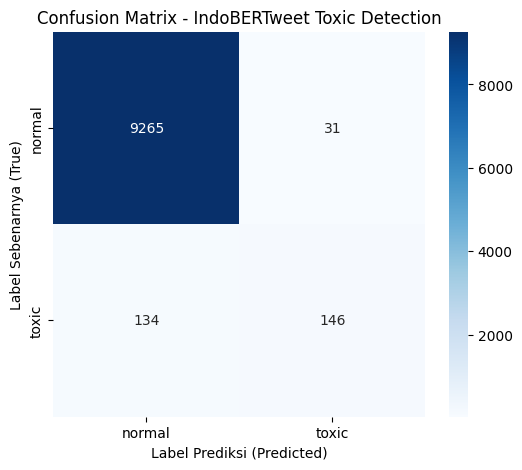

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


In [1]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset

model_path = "./model_indobertweet_chat_toxic_preprocessing_alay"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

print("Memuat model dan tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

print("Memuat dataset testing...")
df_test = pd.read_csv('../resources/test_preprocessing_alay.csv')
df_test = df_test.dropna(subset=['Pesan_Clean', 'Label Toxic'])

label_mapping = {"normal": 0, "toxic": 1}
df_test['Label_Num'] = df_test['Label Toxic'].map(label_mapping)

texts = df_test['Pesan_Clean'].astype(str).tolist()
true_labels = df_test['Label_Num'].tolist()

class InferenceDataset(Dataset):
    def __init__(self, texts, tokenizer, max_len=64):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        encoding = self.tokenizer(
            text, 
            truncation=True, 
            padding='max_length', 
            max_length=self.max_len, 
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten()
        }

test_dataset = InferenceDataset(texts, tokenizer)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Memulai prediksi pada data testing...")
predictions = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        predictions.extend(preds.cpu().numpy())

df_test['Prediksi_Num'] = predictions
df_test['Prediksi_Label'] = df_test['Prediksi_Num'].map({0: "normal", 1: "toxic"})

print("\n" + "="*50)
print("HASIL KLASIFIKASI DATA TESTING (CLASSIFICATION REPORT)")
print("="*50)
print(classification_report(true_labels, predictions, target_names=["normal", "toxic"]))

print("\nMembuat visualisasi Confusion Matrix...")
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["normal", "toxic"], 
            yticklabels=["normal", "toxic"])
plt.ylabel('Label Sebenarnya (True)')
plt.xlabel('Label Prediksi (Predicted)')
plt.title('Confusion Matrix - IndoBERTweet Toxic Detection')
plt.show()

print("\n" + "="*50)
print("DATA BERDASARKAN CONFUSION MATRIX")
print("="*50)

# True Negative (TN): Aslinya Normal, Diprediksi Normal
tn_df = df_test[(df_test['Label_Num'] == 0) & (df_test['Prediksi_Num'] == 0)]
print(f"\nTrue Negatives (TN) - Normal ditebak Normal: {len(tn_df)} data")
print(tn_df[['Pesan','Pesan_Clean', 'Label Toxic', 'Prediksi_Label']].head(10))

# True Positive (TP): Aslinya Toxic, Diprediksi Toxic
tp_df = df_test[(df_test['Label_Num'] == 1) & (df_test['Prediksi_Num'] == 1)]
print(f"\nTrue Positives (TP) - Toxic ditebak Toxic: {len(tp_df)} data")
print(tp_df[['Pesan','Pesan_Clean', 'Label Toxic', 'Prediksi_Label']].head(10))

# False Positive (FP): Aslinya Normal, TAPI Diprediksi Toxic (Salah tangkap / Oversensitive)
fp_df = df_test[(df_test['Label_Num'] == 0) & (df_test['Prediksi_Num'] == 1)]
print(f"\nFalse Positives (FP) - Normal ditebak Toxic: {len(fp_df)} data")
print(fp_df[['Pesan','Pesan_Clean', 'Label Toxic', 'Prediksi_Label']].head(10))

# False Negative (FN): Aslinya Toxic, TAPI Diprediksi Normal (Kecolongan / Undersensitive)
fn_df = df_test[(df_test['Label_Num'] == 1) & (df_test['Prediksi_Num'] == 0)]
print(f"\nFalse Negatives (FN) - Toxic ditebak Normal: {len(fn_df)} data")
print(fn_df[['Pesan','Pesan_Clean', 'Label Toxic', 'Prediksi_Label']].head(10))

Menggunakan device: cuda
Memuat model dan tokenizer...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 4133.11it/s]


Memuat dataset testing...
Memulai prediksi pada data testing...

HASIL KLASIFIKASI DATA TESTING (CLASSIFICATION REPORT)
              precision    recall  f1-score   support

      normal       1.00      0.99      0.99      9481
 judi online       0.35      0.52      0.41        95

    accuracy                           0.99      9576
   macro avg       0.67      0.75      0.70      9576
weighted avg       0.99      0.99      0.99      9576


Membuat visualisasi Confusion Matrix...


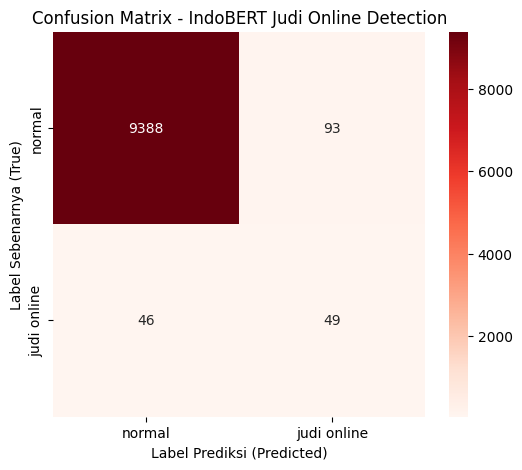

[Output tidak disertakan pada rilis publik. Hanya statistik agregat yang dipublikasikan; teks pesan pengguna, daftar frekuensi kata, dan identitas pengguna dihilangkan. Lihat 'Data & Content Policy' di README.]


In [2]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset

model_path = "./model_indoberttweet_chat_judi_online_preprocessing_typo_correction"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Menggunakan device: {device}")

print("Memuat model dan tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
model.eval()

print("Memuat dataset testing...")
df_test = pd.read_csv('../resources/test_preprocessing_alay_typo_correction.csv')
df_test = df_test.dropna(subset=['Pesan_Clean', 'Label Judi Online'])

label_mapping = {"normal": 0, "judi online": 1}
df_test['Label_Num'] = df_test['Label Judi Online'].map(label_mapping)

texts = df_test['Pesan_Clean'].astype(str).tolist()
true_labels = df_test['Label_Num'].tolist()

class InferenceDataset(Dataset):
    def __init__(self, texts, tokenizer, max_len=64):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        encoding = self.tokenizer(
            text, 
            truncation=True, 
            padding='max_length', 
            max_length=self.max_len, 
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten()
        }

test_dataset = InferenceDataset(texts, tokenizer)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Memulai prediksi pada data testing...")
predictions = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        
        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)
        predictions.extend(preds.cpu().numpy())

df_test['Prediksi_Num'] = predictions
df_test['Prediksi_Label'] = df_test['Prediksi_Num'].map({0: "normal", 1: "judi online"})

print("\n" + "="*50)
print("HASIL KLASIFIKASI DATA TESTING (CLASSIFICATION REPORT)")
print("="*50)
print(classification_report(true_labels, predictions, target_names=["normal", "judi online"]))

print("\nMembuat visualisasi Confusion Matrix...")
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=["normal", "judi online"], 
            yticklabels=["normal", "judi online"])
plt.ylabel('Label Sebenarnya (True)')
plt.xlabel('Label Prediksi (Predicted)')
plt.title('Confusion Matrix - IndoBERT Judi Online Detection')
plt.show()

print("\n" + "="*50)
print("DATA BERDASARKAN CONFUSION MATRIX")
print("="*50)

# True Negative (TN): Aslinya Normal, Diprediksi Normal
tn_df = df_test[(df_test['Label_Num'] == 0) & (df_test['Prediksi_Num'] == 0)]
print(f"\nTrue Negatives (TN) - Normal ditebak Normal: {len(tn_df)} data")
print(tn_df[['Pesan', 'Pesan_Clean', 'Label Judi Online', 'Prediksi_Label']].head(10))

# True Positive (TP): Aslinya Judi, Diprediksi Judi
tp_df = df_test[(df_test['Label_Num'] == 1) & (df_test['Prediksi_Num'] == 1)]
print(f"\nTrue Positives (TP) - Judi ditebak Judi: {len(tp_df)} data")
print(tp_df[['Pesan', 'Pesan_Clean', 'Label Judi Online', 'Prediksi_Label']].head(10))

# False Positive (FP): Aslinya Normal, TAPI Diprediksi Judi (Salah tangkap)
fp_df = df_test[(df_test['Label_Num'] == 0) & (df_test['Prediksi_Num'] == 1)]
print(f"\nFalse Positives (FP) - Normal TAPI ditebak Judi: {len(fp_df)} data")
print(fp_df[['Pesan', 'Pesan_Clean', 'Label Judi Online', 'Prediksi_Label']].head(10)) 

# False Negative (FN): Aslinya Judi, TAPI Diprediksi Normal (Kecolongan)
fn_df = df_test[(df_test['Label_Num'] == 1) & (df_test['Prediksi_Num'] == 0)]
print(f"\nFalse Negatives (FN) - Judi TAPI ditebak Normal: {len(fn_df)} data")
print(fn_df[['Pesan', 'Pesan_Clean', 'Label Judi Online', 'Prediksi_Label']].head(10))